# StyleGAN and StyleGAN2

## Theory, mathematics, and implementation context

StyleGAN maps $z\sim\mathcal N(0,I)$ through an MLP $w=f(z)$ and injects transformed styles into synthesis layers. A learned constant initializes synthesis; per-layer styles control feature statistics at different scales, while spatial noise supplies stochastic detail. Style mixing trains layer ranges to accept different latent sources. The intermediate W space can make edits more linear than raw Z, though disentanglement is not guaranteed.

StyleGAN2 replaces AdaIN-heavy synthesis with weight modulation and demodulation. Given convolution weights $w_{o,i,k}$ and style scales $s_i$, modulated weights are $w'_{o,i,k}=s_iw_{o,i,k}$; demodulation multiplies output channel $o$ by $d_o=(\sum_{i,k}(w'_{o,i,k})^2+\epsilon)^{-1/2}$. Path length regularization penalizes variation in $\|J_w^Ty\|$, encouraging consistent image sensitivity to W-space movement. This compact 32px CIFAR-10 implementation teaches these operations; it is not the fused, high-resolution official training system.

## Case study data and image scale

Use the same fixed 4,096 CIFAR-10 images for comparable examples. Faces are naturally interpretable, but CIFAR-10 avoids external dataset setup.

In [15]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt
torch.manual_seed(7)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
tf=transforms.Compose([transforms.Resize(32),transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
ds=datasets.CIFAR10("./data",train=True,download=True,transform=tf)
loader=DataLoader(Subset(ds,range(4096)),batch_size=64,shuffle=True,num_workers=0,drop_last=True)
print(DEVICE,len(loader.dataset))

Files already downloaded and verified
cpu 4096


## Mapping network and modulated convolution

In [16]:
Z_DIM=W_DIM=128
class Mapping(nn.Module):
    def __init__(self):
        super().__init__(); layers=[]
        for i in range(4): layers += [nn.Linear(Z_DIM if i==0 else W_DIM,W_DIM),nn.LeakyReLU(.2)]
        self.net=nn.Sequential(*layers)
    def forward(self,z): return self.net(F.normalize(z,dim=1))
class ModConv(nn.Module):
    def __init__(self,ci,co,k=3):
        super().__init__(); self.ci=ci; self.co=co; self.k=k; self.weight=nn.Parameter(torch.randn(1,co,ci,k,k)); self.affine=nn.Linear(W_DIM,ci); nn.init.ones_(self.affine.bias)
    def forward(self,x,w):
        b,_,h,ww=x.shape; wt=self.weight*self.affine(w).view(b,1,self.ci,1,1)
        wt=wt*torch.rsqrt(wt.square().sum((2,3,4),keepdim=True)+1e-8)
        y=F.conv2d(x.reshape(1,b*self.ci,h,ww),wt.reshape(b*self.co,self.ci,self.k,self.k),padding=self.k//2,groups=b)
        return y.reshape(b,self.co,h,ww)

## Compact style synthesis network

This teaching version reuses one W vector per image. Full StyleGAN has distinct style inputs per convolution and ToRGB operation, enabling true coarse-to-fine style mixing.

In [17]:
BASE_CHANNELS=128
class StyleBlock(nn.Module):
    def __init__(self,ci,co):
        super().__init__(); self.a=ModConv(ci,co); self.b=ModConv(co,co); self.na=nn.Parameter(torch.zeros(1,co,1,1)); self.nb=nn.Parameter(torch.zeros(1,co,1,1))
    def forward(self,x,w):
        x=F.interpolate(x,scale_factor=2,mode="nearest"); x=F.leaky_relu(self.a(x,w)+torch.randn_like(x[:,:1])*self.na,.2)
        return F.leaky_relu(self.b(x,w)+torch.randn_like(x[:,:1])*self.nb,.2)
class StyleGenerator(nn.Module):
    def __init__(self):
        super().__init__(); self.mapping=Mapping(); self.const=nn.Parameter(torch.randn(1,BASE_CHANNELS,4,4)); self.start=ModConv(BASE_CHANNELS,BASE_CHANNELS)
        self.blocks=nn.ModuleList([StyleBlock(BASE_CHANNELS,64),StyleBlock(64,32),StyleBlock(32,16)]); self.rgb=nn.ModuleList([nn.Conv2d(c,3,1) for c in (BASE_CHANNELS,64,32,16)])
    def forward(self,z):
        w=self.mapping(z); x=F.leaky_relu(self.start(self.const.expand(len(z),-1,-1,-1),w),.2)
        for block in self.blocks: x=block(x,w)
        return torch.tanh(self.rgb[-1](x)),w
G=StyleGenerator().to(DEVICE); print(G(torch.randn(2,128,device=DEVICE))[0].shape)


torch.Size([2, 3, 32, 32])


## Style mixing and truncation

Truncation moves W toward its running mean: $w'=ar w+\psi(w-ar w)$. Lower $\psi$ often raises typical fidelity while reducing variety. This shared-style model cannot demonstrate actual layer-wise edits, but the helper describes the data flow.

In [18]:
def truncate(w,w_avg,psi=.7): return w_avg+psi*(w-w_avg)
def mix_styles(w1,w2,num_layers,cutoff): return [w1 if i<cutoff else w2 for i in range(num_layers)]
G=StyleGenerator().to(DEVICE); w1=G.mapping(torch.randn(4,128,device=DEVICE)); w2=G.mapping(torch.randn(4,128,device=DEVICE))
print(len(mix_styles(w1,w2,8,3)),truncate(w1,w1.mean(0)).shape)

8 torch.Size([4, 128])


## Path length regularization

Random image-space noise probes the Jacobian from W to image. The squared difference between gradient norms and a moving target is the regularizer. It requires higher-order gradients and is usually applied lazily.

In [19]:
def path_length_penalty(images,w,mean_length=0.,decay=.99):
    noise=torch.randn_like(images)/(images.shape[-1]*images.shape[-2])**.5
    grad=torch.autograd.grad((images*noise).sum(),w,create_graph=True)[0]
    lengths=(grad.square().sum(1)+1e-8).sqrt(); mean=decay*mean_length+(1-decay)*lengths.mean().detach()
    return (lengths-mean).square().mean(),mean
w=torch.randn(2,128,device=DEVICE,requires_grad=True); probe=w[:,0,None,None,None]*torch.ones(2,3,8,8,device=DEVICE)
print(path_length_penalty(probe,w)[0])

tensor(0.7683)


## Stabilized training loop (run before sampling)

The initial 40-epoch run collapsed to nearly black samples. This version constrains the discriminator with spectral normalization and lazy R1 regularization, trains for 80 epochs, and keeps an exponential moving average (EMA) of generator weights for smoother sampling. It uses 4,096 CIFAR-10 images and a smaller channel width. On CPU the longer run may take several minutes; wait for this cell to finish before sampling.


epoch 01/80 | D=0.913 | G=1.006 | 24.3s
epoch 02/80 | D=0.649 | G=2.084 | 22.7s
epoch 03/80 | D=0.407 | G=2.693 | 22.2s
epoch 04/80 | D=0.153 | G=4.387 | 22.3s
epoch 05/80 | D=0.131 | G=4.892 | 22.5s
epoch 06/80 | D=0.095 | G=5.390 | 22.3s
epoch 07/80 | D=0.077 | G=5.666 | 22.0s
epoch 08/80 | D=0.411 | G=3.731 | 22.2s
epoch 09/80 | D=0.566 | G=1.721 | 22.3s
epoch 10/80 | D=0.795 | G=1.892 | 22.4s
epoch 11/80 | D=0.655 | G=2.342 | 22.2s
epoch 12/80 | D=0.877 | G=1.179 | 25.9s
epoch 13/80 | D=0.810 | G=1.778 | 24.5s
epoch 14/80 | D=0.903 | G=1.325 | 24.9s
epoch 15/80 | D=0.975 | G=1.652 | 25.0s
epoch 16/80 | D=0.937 | G=1.183 | 26.1s
epoch 17/80 | D=0.685 | G=2.191 | 25.2s
epoch 18/80 | D=0.873 | G=1.567 | 25.2s
epoch 19/80 | D=0.968 | G=1.339 | 25.9s
epoch 20/80 | D=1.184 | G=1.201 | 25.5s
epoch 21/80 | D=1.015 | G=1.192 | 25.3s
epoch 22/80 | D=1.105 | G=1.204 | 26.5s
epoch 23/80 | D=1.148 | G=1.153 | 26.5s
epoch 24/80 | D=1.030 | G=1.308 | 25.5s
epoch 25/80 | D=1.051 | G=1.251 | 24.8s


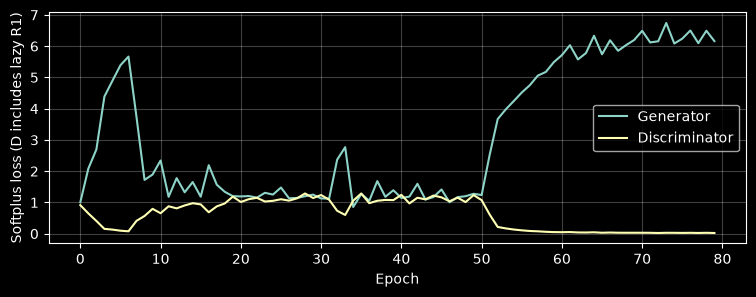

In [20]:
from copy import deepcopy
from torch.nn.utils import spectral_norm
import time
class Disc(nn.Module):
    def __init__(self):
        super().__init__(); self.net=nn.Sequential(spectral_norm(nn.Conv2d(3,32,4,2,1)),nn.LeakyReLU(.2),spectral_norm(nn.Conv2d(32,64,4,2,1)),nn.LeakyReLU(.2),spectral_norm(nn.Conv2d(64,128,4,2,1)),nn.LeakyReLU(.2),nn.Flatten(),nn.Linear(128*4*4,1))
    def forward(self,x): return self.net(x)
EPOCHS=80
R1_INTERVAL=16; R1_GAMMA=2.0; EMA_BETA=0.995
G=StyleGenerator().to(DEVICE); D=Disc().to(DEVICE); G_ema=deepcopy(G).eval()
for parameter in G_ema.parameters(): parameter.requires_grad_(False)
optD=torch.optim.Adam(D.parameters(),lr=1e-4,betas=(0,.99)); optG=torch.optim.Adam(G.parameters(),lr=2e-4,betas=(0,.99))
g_history=[]; d_history=[]; step=0
for epoch in range(EPOCHS):
    G.train(); D.train(); g_running=0.0; d_running=0.0; started=time.time()
    for real,_ in loader:
        real=real.to(DEVICE).requires_grad_(True); b=len(real)
        fake=G(torch.randn(b,128,device=DEVICE))[0].detach()
        real_logits=D(real); fake_logits=D(fake)
        d_loss=F.softplus(-real_logits).mean()+F.softplus(fake_logits).mean()
        if step % R1_INTERVAL == 0:
            real_grad=torch.autograd.grad(real_logits.sum(),real,create_graph=True)[0]
            r1_penalty=real_grad.square().flatten(1).sum(1).mean()
            d_loss=d_loss+(R1_GAMMA*R1_INTERVAL/2)*r1_penalty
        optD.zero_grad(set_to_none=True); d_loss.backward(); optD.step()
        for parameter in D.parameters(): parameter.requires_grad_(False)
        g_loss=F.softplus(-D(G(torch.randn(b,128,device=DEVICE))[0])).mean()
        optG.zero_grad(set_to_none=True); g_loss.backward(); optG.step()
        for parameter in D.parameters(): parameter.requires_grad_(True)
        with torch.no_grad():
            for ema_parameter,parameter in zip(G_ema.parameters(),G.parameters()): ema_parameter.lerp_(parameter,1-EMA_BETA)
        g_running+=g_loss.item(); d_running+=d_loss.item(); step+=1
    g_history.append(g_running/len(loader)); d_history.append(d_running/len(loader))
    print(f"epoch {epoch+1:02d}/{EPOCHS} | D={d_history[-1]:.3f} | G={g_history[-1]:.3f} | {time.time()-started:.1f}s")
plt.figure(figsize=(9,3)); plt.plot(g_history,label="Generator"); plt.plot(d_history,label="Discriminator"); plt.xlabel("Epoch"); plt.ylabel("Softplus loss (D includes lazy R1)"); plt.legend(); plt.grid(alpha=.25)


## Latent interpolation and comparison

Smooth interpolation finds artifacts but does not prove disentanglement. Fixed noise helps isolate styles from stochastic texture. ProGAN is a resolution curriculum; StyleGAN emphasizes layer-wise synthesis; StyleGAN2 improves signal behavior and artifact quality.

sample range: 0.9996947646141052 1.0


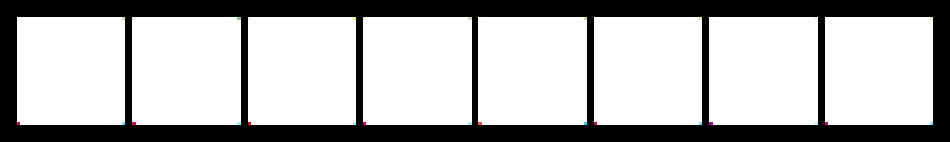

In [21]:
G_ema.eval()
with torch.no_grad():
    a=torch.randn(1,128,device=DEVICE); b=torch.randn(1,128,device=DEVICE)
    imgs=torch.cat([G_ema(slerp(a,b,t))[0] for t in torch.linspace(0,1,8,device=DEVICE)]).cpu()
print("sample range:",float(imgs.min()),float(imgs.max()))
plt.figure(figsize=(12,2)); plt.axis("off"); plt.imshow(utils.make_grid(imgs,nrow=8,normalize=True,scale_each=True).permute(1,2,0));


## Key Takeaways

- The mapping network transforms Z into W; per-layer affine styles steer synthesis at multiple scales.
- Noise injection adds localized stochastic detail.
- StyleGAN2 uses weight modulation/demodulation to control activation scale and reduce artifacts.
- Path length regularization targets consistent sensitivity to W movement.
- Truncation trades diversity for typicality; style mixing trains layer flexibility.
- Reproduction quality needs more data, resolution, compute, and optimized kernels.